# DSCI 552 — Homework 7

- **Name:** Yiming Lu
- **GitHub Username:** YeeDaco

All imports are in the first code cell (see `requirements.txt`). The data is loaded by the relative path `../data/anuran_calls/`, so the notebook should be run from the `notebook/` folder. Every random step uses the seed `SEED = 552`.

In [1]:
import os
os.environ.setdefault("LOKY_MAX_CPU_COUNT", str(os.cpu_count()))

from pathlib import Path
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline
from joblib import Parallel, delayed
from scipy.cluster.hierarchy import dendrogram, linkage
from scipy.spatial.distance import squareform
from sklearn.cluster import KMeans
from sklearn.metrics import (ConfusionMatrixDisplay, accuracy_score, balanced_accuracy_score,
                             calinski_harabasz_score, f1_score, multilabel_confusion_matrix,
                             precision_score, recall_score, roc_auc_score, roc_curve, silhouette_score)
from sklearn.model_selection import GridSearchCV, StratifiedKFold, train_test_split
from sklearn.multiclass import OneVsRestClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, label_binarize
from sklearn.svm import SVC, LinearSVC
from threadpoolctl import threadpool_limits

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 160)
SEED = 552
N_JOBS = -1
LABELS = ["Family", "Genus", "Species"]

## 1. Multi-class and Multi-Label Classification Using Support Vector Machines

### (a) Anuran Calls (MFCCs) data

The data was downloaded from the UCI repository and is stored in `../data/anuran_calls/`. It has 7,195 syllables of frog calls, 22 MFCC features (`MFCCs_ 1`, …, `MFCCs_22`), three labels (`Family`, `Genus`, `Species`) and the `RecordID` of the recording the syllable was cut from. `RecordID` is an identifier, not a feature, so it is not used. 70% of the rows are chosen at random as the training set; the other 30% are the test set.

In [2]:
DATA = Path("../data/anuran_calls")
frogs = pd.read_csv(DATA / "Frogs_MFCCs.csv")
features = [c for c in frogs.columns if c.startswith("MFCCs")]
X_all = frogs[features].to_numpy()
Y_all = frogs[LABELS]
print("shape:", frogs.shape, "| features:", len(features), "| missing values:", frogs.isna().sum().sum())

X_train, X_test, Y_train, Y_test = train_test_split(X_all, Y_all, train_size=0.7, random_state=SEED)
Y_train, Y_test = Y_train.reset_index(drop=True), Y_test.reset_index(drop=True)
print("training set:", X_train.shape, "| test set:", X_test.shape)

counts = pd.concat({lab: pd.concat({"all": Y_all[lab].value_counts(), "train": Y_train[lab].value_counts(),
                                    "test": Y_test[lab].value_counts()}, axis=1) for lab in LABELS})
counts

shape: (7195, 26) | features: 22 | missing values: 0
training set: (5036, 22) | test set: (2159, 22)


all  train  test
Family  Leptodactylidae         4420   3088  1332
        Hylidae                 2165   1516   649
        Dendrobatidae            542    384   158
        Bufonidae                 68     48    20
Genus   Adenomera               4150   2902  1248
        Hypsiboas               1593   1107   486
        Ameerega                 542    384   158
        Dendropsophus            310    221    89
        Leptodactylus            270    186    84
        Scinax                   148    101    47
        Osteocephalus            114     87    27
        Rhinella                  68     48    20
Species AdenomeraHylaedactylus  3478   2433  1045
        HypsiboasCordobae       1121    774   347
        AdenomeraAndre           672    469   203
        Ameeregatrivittata       542    384   158
        HypsiboasCinerascens     472    333   139
        HylaMinuta               310    221    89
        LeptodactylusFuscus      270    186    84
        ScinaxRuber              148    101    47
        OsteocephalusOophagus    114     87    27
        Rhinellagranulosa         68     48    20

In [3]:
frogs[features].describe().T[["mean", "std", "min", "max"]].round(3).T

,MFCCs_ 1,MFCCs_ 2,MFCCs_ 3,MFCCs_ 4,MFCCs_ 5,MFCCs_ 6,MFCCs_ 7,MFCCs_ 8,MFCCs_ 9,MFCCs_10,MFCCs_11,MFCCs_12,MFCCs_13,MFCCs_14,MFCCs_15,MFCCs_16,MFCCs_17,MFCCs_18,MFCCs_19,MFCCs_20,MFCCs_21,MFCCs_22
mean,0.990,0.324,0.311,0.446,0.127,0.098,-0.001,-0.000,0.128,0.056,-0.116,0.043,0.151,-0.039,-0.102,0.042,0.089,0.008,-0.049,-0.053,0.037,0.088
std,0.069,0.219,0.264,0.160,0.163,0.120,0.171,0.116,0.179,0.127,0.187,0.156,0.207,0.153,0.188,0.120,0.138,0.085,0.083,0.094,0.079,0.123
min,-0.251,-0.673,-0.436,-0.473,-0.636,-0.410,-0.539,-0.577,-0.587,-0.952,-0.902,-0.799,-0.644,-0.590,-0.717,-0.499,-0.421,-0.759,-0.681,-0.362,-0.431,-0.379
max,1.000,1.000,1.000,1.000,0.752,0.964,1.000,0.552,0.738,0.523,0.523,0.691,0.946,0.576,0.669,0.671,0.681,0.614,0.574,0.468,0.390,0.432


All features lie in $[-1, 1]$ (each row was divided by its largest absolute MFCC), and their standard deviations are of the same order (0.07–0.26), so the attributes are already normalized, as the footnotes say. All three labels are strongly imbalanced: e.g. `Leptodactylidae` has 4,420 rows and `Bufonidae` only 68; `AdenomeraHylaedactylus` has 3,478 rows and `Rhinellagranulosa` 68.

### (b) Binary relevance: one classifier per label

#### i. Exact match and Hamming score / loss

Let $n$ be the number of test instances and $L = 3$ the number of labels (Family, Genus, Species). For instance $i$ the true label vector is $\mathbf y_i = (y_{i1}, y_{i2}, y_{i3})$ and the prediction is $\hat{\mathbf y}_i$.

- **Exact match ratio** (subset accuracy): $\displaystyle EM = \frac1n\sum_{i=1}^n \mathbb 1[\hat{\mathbf y}_i = \mathbf y_i]$, the fraction of instances for which *all three* labels are correct. It is the strictest measure: one wrong label makes the whole instance wrong.
- **Hamming distance** of instance $i$: $\displaystyle HD_i = \sum_{j=1}^{L}\mathbb 1[\hat y_{ij} \ne y_{ij}] \in \{0, 1, 2, 3\}$, the number of wrong labels.
- **Hamming loss**: $\displaystyle HL = \frac{1}{nL}\sum_{i=1}^n HD_i$, the fraction of wrong (instance, label) pairs. It gives partial credit: an instance with one wrong label costs 1/3 of an instance with three wrong labels.
- **Hamming score**: $HS = 1 - HL$, the fraction of correct (instance, label) pairs; here it is the average of the three per-label accuracies.

In the literature (e.g. Sorower, *A Literature Survey on Algorithms for Multi-label Learning*) the labels are also often written as binary indicator vectors over all $4 + 8 + 10 = 22$ classes, and the "Hamming score" (also called multi-label accuracy) is the Jaccard index $\frac1n\sum_i |Y_i \cap Z_i| / |Y_i \cup Z_i|$ between the true and predicted sets of classes. Since every instance has exactly one class per label, $|Y_i\cap Z_i| = 3 - HD_i$ and $|Y_i \cup Z_i| = 3 + HD_i$, so this Jaccard score is $\frac1n\sum_i \frac{3-HD_i}{3+HD_i}$. Both versions are reported below; the Hamming loss over the 22 binary indicators is just $2HD_i/22$ per instance, a rescaled version of the one above.

In [4]:
def multilabel_scores(Y_true, Y_pred):
    wrong = np.asarray(Y_true) != np.asarray(Y_pred)
    hd = wrong.sum(axis=1)
    out = {"exact match": np.mean(hd == 0), "Hamming loss": wrong.mean(), "Hamming score": 1 - wrong.mean(),
           "avg Hamming distance": hd.mean(), "Jaccard score": np.mean((3 - hd) / (3 + hd))}
    out.update({f"{lab} accuracy": 1 - wrong[:, j].mean() for j, lab in enumerate(LABELS)})
    return out


results = {}         # test-set multi-label scores of every model
fitted = {}          # fitted per-label models
predictions = {}     # test-set predictions


def evaluate(name, models):
    # models: dict label -> fitted classifier. Returns the train/test multi-label scores.
    fitted[name] = models
    P_train = pd.DataFrame({lab: models[lab].predict(X_train) for lab in LABELS})
    P_test = pd.DataFrame({lab: models[lab].predict(X_test) for lab in LABELS})
    predictions[name] = P_test
    table = pd.DataFrame({"train": multilabel_scores(Y_train, P_train), "test": multilabel_scores(Y_test, P_test)}).T
    results[name] = table.loc["test"]
    return table.round(4)

#### ii. Gaussian-kernel SVMs, one versus all

For each label a separate SVM is trained. `SVC` in scikit-learn uses one-versus-one for more than two classes, so it is wrapped in `OneVsRestClassifier`: for a label with $K$ classes, $K$ binary RBF SVMs (class $k$ vs. the rest) are trained, and an instance gets the class with the largest decision value.

The Gaussian kernel is $K(x, x') = \exp\left(-\|x-x'\|^2 / (2\sigma^2)\right)$, i.e. scikit-learn's `gamma` $= 1/(2\sigma^2)$. The weight of the SVM penalty is `C` (the weight of the slack/hinge term). Both are chosen by **10-fold stratified cross-validation** on the training set, separately for each label, with CV accuracy as the criterion.

**Ranges.** Following the footnote, I first fitted the SVM on the whole training set with very small and very large values of both parameters and kept the ranges for which the training accuracy does not fall below 70% (checked in the next cell; a quick exploration showed that larger $\sigma$ or smaller $C$ quickly drop the accuracy, and $\sigma$ much smaller than the lower ends overfits and becomes very slow). The grids are

- $C \in \{10^{-1}, 10^{0}, \dots, 10^{5}\}$ (increments in $\log C$),
- raw attributes: $\sigma \in \{0.2, 0.4, \dots, 1.0\}$; standardized attributes: $\sigma \in \{2, 4, \dots, 10\}$ (linear increments).

The $\sigma$ grids differ because standardizing multiplies every feature by $1/s_j \approx 4$–14, which makes all distances about 7 times larger. The model is tried with both the raw (already normalized) and the standardized attributes. For the standardized version, the `StandardScaler` is inside the pipeline, so it is fitted on the training folds only.

In [5]:
cv10 = StratifiedKFold(n_splits=10, shuffle=True, random_state=SEED)
C_GRID = 10.0 ** np.arange(-1, 6)
SIGMA = {"raw": np.round(np.arange(0.2, 1.01, 0.2), 1), "standardized": np.arange(2.0, 10.1, 2.0)}


def gamma_of(sigma):
    return 1 / (2 * np.asarray(sigma) ** 2)


def rbf_model(scaling, C=1.0, sigma=1.0):
    ovr = OneVsRestClassifier(SVC(kernel="rbf", C=C, gamma=gamma_of(sigma), cache_size=1000))
    steps = [("scale", StandardScaler())] if scaling == "standardized" else []
    return Pipeline(steps + [("svm", ovr)])


def train_acc(scaling, lab, C, sigma):
    m = rbf_model(scaling, C, sigma).fit(X_train, Y_train[lab])
    return {"scaling": scaling, "label": lab, "C": C, "sigma": sigma, "train accuracy": m.score(X_train, Y_train[lab])}


corners = [(s, lab, C, sig) for s in SIGMA for lab in LABELS for C in (C_GRID[0], C_GRID[-1])
           for sig in (SIGMA[s][0], SIGMA[s][-1])]
range_check = pd.DataFrame(Parallel(n_jobs=N_JOBS)(delayed(train_acc)(*c) for c in corners))
print("lowest training accuracy at the corners of the grid: %.3f" % range_check["train accuracy"].min())
range_check.pivot_table(index=["scaling", "C", "sigma"], columns="label", values="train accuracy").round(3)

lowest training accuracy at the corners of the grid: 0.889


label                        Family  Genus  Species
scaling      C        sigma                        
raw          0.1      0.2     0.990  0.982    0.995
                      1.0     0.948  0.915    0.918
             100000.0 0.2     1.000  1.000    1.000
                      1.0     1.000  1.000    1.000
standardized 0.1      2.0     0.982  0.982    0.987
                      10.0    0.920  0.889    0.893
             100000.0 2.0     1.000  1.000    1.000
                      10.0    1.000  1.000    1.000

At every corner of both grids the training accuracy is above 70% for all three labels, so the grids satisfy the rule of thumb. Now the 10-fold CV over the $7 \times 5 = 35$ combinations, for each label and for both scalings:

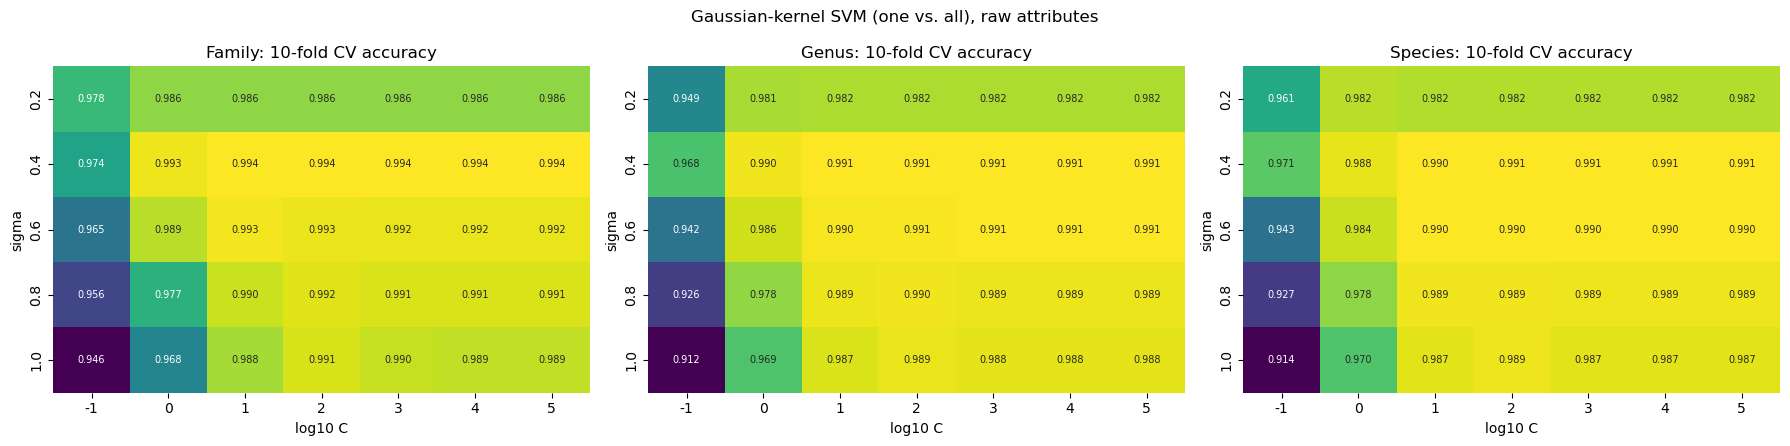

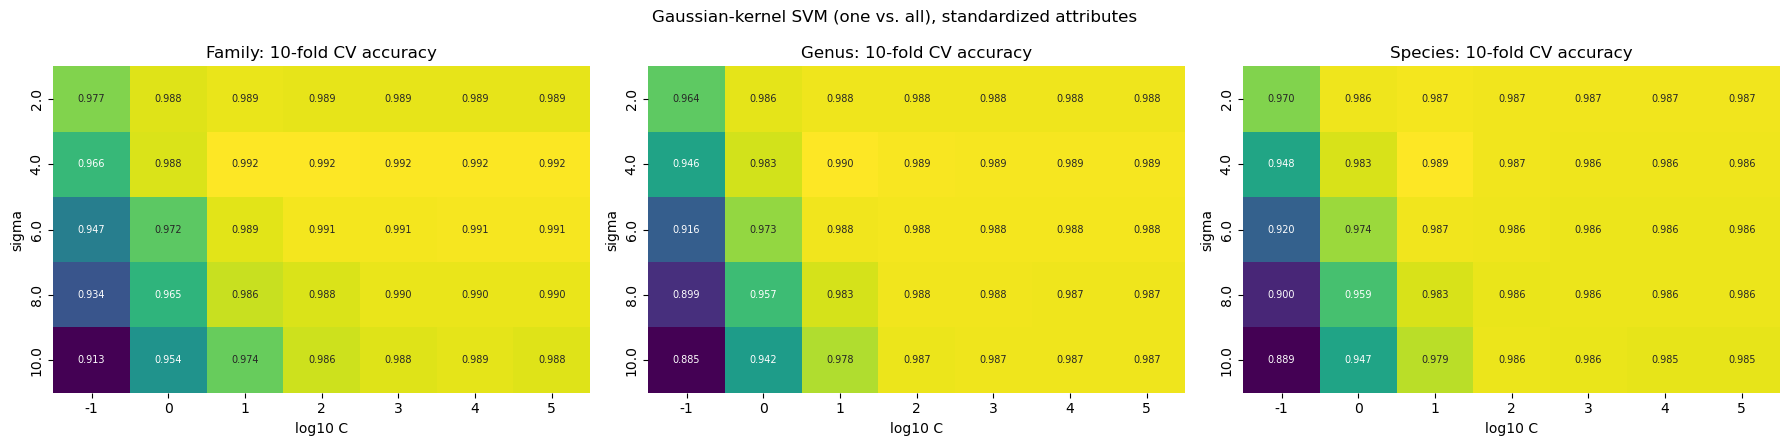

best C  best sigma  CV accuracy  test accuracy  seconds
attributes   label                                                           
raw          Family    100.0         0.4       0.9940         0.9921     33.3
             Genus      10.0         0.4       0.9915         0.9889     53.2
             Species   100.0         0.4       0.9907         0.9880     62.0
standardized Family     10.0         4.0       0.9923         0.9903     31.3
             Genus      10.0         4.0       0.9903         0.9880     42.2
             Species    10.0         4.0       0.9889         0.9875     47.2

In [6]:
def cv_rbf(scaling):
    grid = {"svm__estimator__C": C_GRID, "svm__estimator__gamma": gamma_of(SIGMA[scaling])}
    models, rows, surfaces = {}, [], {}
    for lab in LABELS:
        t0 = time.time()
        gs = GridSearchCV(rbf_model(scaling), grid, cv=cv10, scoring="accuracy", n_jobs=N_JOBS).fit(X_train, Y_train[lab])
        models[lab] = gs.best_estimator_
        C, g = gs.best_params_["svm__estimator__C"], gs.best_params_["svm__estimator__gamma"]
        rows.append({"label": lab, "best C": C, "best sigma": round(float(np.sqrt(1 / (2 * g))), 2),
                     "CV accuracy": gs.best_score_, "test accuracy": gs.best_estimator_.score(X_test, Y_test[lab]),
                     "seconds": round(time.time() - t0, 1)})
        cvr = pd.DataFrame(gs.cv_results_)
        cvr["sigma"] = np.round(np.sqrt(1 / (2 * cvr["param_svm__estimator__gamma"].astype(float))), 2)
        cvr["log10 C"] = np.log10(cvr["param_svm__estimator__C"].astype(float)).round(0).astype(int)
        surfaces[lab] = cvr.pivot(index="sigma", columns="log10 C", values="mean_test_score")
    return models, pd.DataFrame(rows).set_index("label"), surfaces


def plot_surfaces(surfaces, title):
    fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
    for ax, lab in zip(axes, LABELS):
        sns.heatmap(surfaces[lab], annot=True, fmt=".3f", cmap="viridis", ax=ax, cbar=False, annot_kws={"size": 7})
        ax.set_title(f"{lab}: 10-fold CV accuracy")
    fig.suptitle(title)
    plt.tight_layout()
    plt.show()


rbf_models, rbf_cv, rbf_surf = {}, {}, {}
for scaling in SIGMA:
    rbf_models[scaling], rbf_cv[scaling], rbf_surf[scaling] = cv_rbf(scaling)
    plot_surfaces(rbf_surf[scaling], f"Gaussian-kernel SVM (one vs. all), {scaling} attributes")
pd.concat(rbf_cv, names=["attributes"]).round(4)

In [7]:
for scaling in SIGMA:
    print(f"Gaussian SVM, {scaling} attributes")
    display(evaluate(f"Gaussian SVM ({scaling})", rbf_models[scaling]))

Gaussian SVM, raw attributes


,exact match,Hamming loss,Hamming score,avg Hamming distance,Jaccard score,Family accuracy,Genus accuracy,Species accuracy
train,1.000,0.0000,1.0000,0.000,1.0000,1.0000,1.0000,1.000
test,0.987,0.0103,0.9897,0.031,0.9887,0.9921,0.9889,0.988


Gaussian SVM, standardized attributes


,exact match,Hamming loss,Hamming score,avg Hamming distance,Jaccard score,Family accuracy,Genus accuracy,Species accuracy
train,0.9994,0.0005,0.9995,0.0014,0.9995,0.9996,0.9996,0.9994
test,0.9856,0.0114,0.9886,0.0343,0.9876,0.9903,0.9880,0.9875


**Discussion.** For both versions of the attributes the CV surface is a ridge: very small $C$ with large $\sigma$ underfits, very small $\sigma$ (raw 0.2, standardized 2) slightly overfits, and the optimum lies inside the grid, not on its edge. CV chooses $\sigma = 0.4$ with $C = 10$–100 on the raw attributes and $\sigma = 4$ with $C = 10$ on the standardized ones. All three labels are predicted with about 99% accuracy. On the test set the raw attributes are marginally better (exact match 0.9870, Hamming loss 0.0103) than the standardized ones (0.9856, 0.0114). The difference is 3 of 2,159 instances, so standardizing neither helps nor hurts. This is expected because the MFCCs are already on a common scale. The CV accuracies (0.989–0.994) agree with the test accuracies (0.988–0.992).

The exact-match error (1.3%) is much smaller than three times the Hamming loss (3.1%): when an instance is wrong, on average 2.4 of its 3 labels are wrong. The labels are hierarchical (species determines genus and family), so a syllable that is confused with another species is usually also given the wrong genus and family.

*Caveat:* syllables cut from the same recording (`RecordID`) appear in both the training and the test set, so these accuracies measure how well syllables of *known* individual frogs are recognized. They are optimistic for frogs that were never recorded before.

#### iii. L1-penalized SVMs

Following the convention, the $\mathscr L_1$ penalty is used with a **linear** kernel: `LinearSVC(penalty="l1", loss="squared_hinge", dual=False)` minimizes $\|w\|_1 + C\sum_i \max(0, 1 - y_i w^\top x_i)^2$ for each binary problem, and for multi-class labels it is one versus all (one sparse $w$ per class). The attributes are standardized (`StandardScaler` inside the pipeline, fitted on the training folds only). $C$ is chosen by 10-fold stratified CV over $C \in \{10^{-3}, 10^{-2}, \dots, 10^{3}\}$ (the training accuracy is far above 70% already at $C = 10^{-3}$ and does not change any more above $C = 1$).

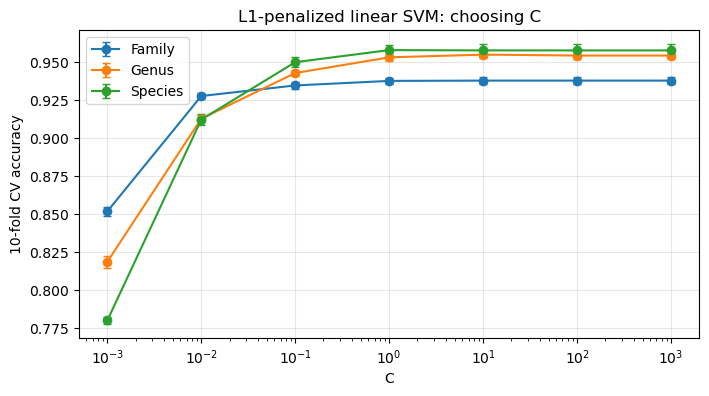

,best C,CV accuracy,test accuracy,zero weights,seconds
label,,,,,
Family,10.0,0.9378,0.9319,0 / 88,10.2
Genus,10.0,0.9549,0.9523,0 / 176,21.7
Species,1.0,0.9579,0.9565,5 / 220,25.7


,exact match,Hamming loss,Hamming score,avg Hamming distance,Jaccard score,Family accuracy,Genus accuracy,Species accuracy
train,0.9218,0.0468,0.9532,0.1404,0.9445,0.9394,0.9579,0.9623
test,0.9162,0.0531,0.9469,0.1593,0.9383,0.9319,0.9523,0.9565


In [8]:
C_L1 = 10.0 ** np.arange(-3, 4)


def l1_svm():
    return LinearSVC(penalty="l1", loss="squared_hinge", dual=False, tol=1e-3, max_iter=20000, random_state=SEED)


def cv_linear(make_pipe, name):
    models, rows, curves = {}, [], {}
    for lab in LABELS:
        t0 = time.time()
        gs = GridSearchCV(make_pipe(), {"svm__C": C_L1}, cv=cv10, scoring="accuracy", n_jobs=N_JOBS).fit(X_train, Y_train[lab])
        models[lab] = gs.best_estimator_
        coef = gs.best_estimator_.named_steps["svm"].coef_
        rows.append({"label": lab, "best C": gs.best_params_["svm__C"], "CV accuracy": gs.best_score_,
                     "test accuracy": gs.best_estimator_.score(X_test, Y_test[lab]),
                     "zero weights": f"{(coef == 0).sum()} / {coef.size}", "seconds": round(time.time() - t0, 1)})
        curves[lab] = pd.DataFrame({"mean": gs.cv_results_["mean_test_score"],
                                    "se": gs.cv_results_["std_test_score"] / np.sqrt(10)}, index=C_L1)
    fig, ax = plt.subplots(figsize=(8, 4))
    for lab in LABELS:
        ax.errorbar(curves[lab].index, curves[lab]["mean"], yerr=curves[lab]["se"], marker="o", capsize=3, label=lab)
    ax.set_xscale("log")
    ax.set_xlabel("C")
    ax.set_ylabel("10-fold CV accuracy")
    ax.set_title(f"{name}: choosing C")
    ax.grid(alpha=0.3)
    ax.legend()
    plt.show()
    return models, pd.DataFrame(rows).set_index("label")


l1_models, l1_cv = cv_linear(lambda: Pipeline([("scale", StandardScaler()), ("svm", l1_svm())]), "L1-penalized linear SVM")
display(l1_cv.round(4))
evaluate("L1 linear SVM", l1_models)

**Discussion.** The L1-penalized linear SVM is clearly worse than the Gaussian SVM: exact match 0.9162 vs. 0.9870, and Hamming loss 0.0531 vs. 0.0103. A linear boundary in the 22 MFCCs cannot separate the classes as well as the RBF kernel can. The CV curves are flat for $C \ge 1$; CV chooses $C = 10$ for Family and Genus and $C = 1$ for Species. At these values the L1 penalty is weak, so almost no weights are exactly zero (0 of 88, 0 of 176 and 5 of 220). All MFCCs are useful, and a stronger penalty (smaller $C$) only loses accuracy. The train and test scores are close (exact match 0.922 vs. 0.916), so the linear model is limited by bias, not variance. Family, the label with the fewest classes, has the lowest accuracy (0.932): Bufonidae and Hylidae are not linearly separable from the large Leptodactylidae class.

#### iv. L1-penalized SVMs with SMOTE

SMOTE (synthetic minority over-sampling) creates new points of a minority class on the line segments between a point of that class and one of its $k = 5$ nearest neighbours of the same class. For a multi-class label, every class except the largest is over-sampled up to the size of the largest class. SMOTE is placed **inside** the cross-validation pipeline (`imblearn` pipeline: standardize → SMOTE → L1 SVM), so in each fold only the training folds are over-sampled and the validation fold keeps the real class distribution; the final model is fitted with SMOTE on the whole training set and evaluated on the untouched test set. $C$ is again chosen by 10-fold CV over the same grid.

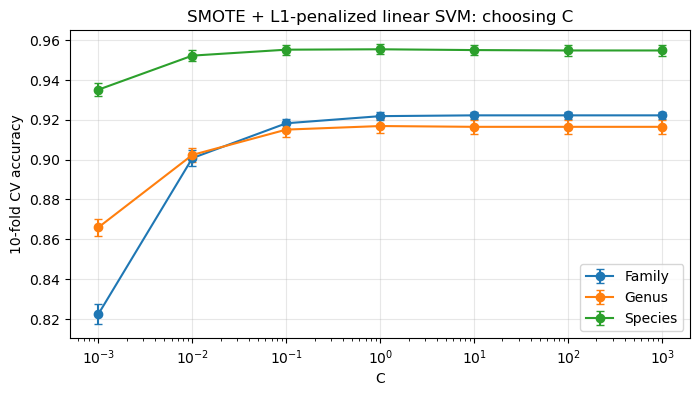

,best C,CV accuracy,test accuracy,zero weights,seconds
label,,,,,
Family,10.0,0.9222,0.9125,0 / 88,43.4
Genus,1.0,0.9168,0.9092,0 / 176,173.0
Species,1.0,0.9553,0.9486,2 / 220,218.3


,exact match,Hamming loss,Hamming score,avg Hamming distance,Jaccard score,Family accuracy,Genus accuracy,Species accuracy
train,0.8707,0.0629,0.9371,0.1886,0.9190,0.9234,0.9249,0.9631
test,0.8606,0.0766,0.9234,0.2297,0.9058,0.9125,0.9092,0.9486


In [9]:
smote_models, smote_cv = cv_linear(lambda: ImbPipeline([("scale", StandardScaler()), ("smote", SMOTE(k_neighbors=5, random_state=SEED)),
                                                        ("svm", l1_svm())]), "SMOTE + L1-penalized linear SVM")
display(smote_cv.round(4))
evaluate("SMOTE + L1 linear SVM", smote_models)

Accuracy-based scores hide what happens to the small classes. The per-label balanced accuracy (mean of the per-class recalls) and macro-averaged $F_1$ on the test set show the effect of the class imbalance and of SMOTE:

In [10]:
def per_label_table(names):
    rows = []
    for name in names:
        for lab in LABELS:
            y, p = Y_test[lab], predictions[name][lab]
            rec = recall_score(y, p, average=None, labels=sorted(y.unique()))
            rows.append({"model": name, "label": lab, "accuracy": accuracy_score(y, p),
                         "balanced accuracy": balanced_accuracy_score(y, p), "macro F1": f1_score(y, p, average="macro"),
                         "lowest class recall": rec.min(),
                         "class with lowest recall": sorted(y.unique())[rec.argmin()]})
    return pd.DataFrame(rows).set_index(["label", "model"]).sort_index(level=0, sort_remaining=False)


per_label = per_label_table(list(predictions))
per_label.round(4)

accuracy  balanced accuracy  macro F1  lowest class recall class with lowest recall
label   model                                                                                                           
Family  Gaussian SVM (raw)             0.9921             0.9593    0.9630               0.8500                Bufonidae
        Gaussian SVM (standardized)    0.9903             0.9697    0.9634               0.9000                Bufonidae
        L1 linear SVM                  0.9319             0.6916    0.6860               0.0000                Bufonidae
        SMOTE + L1 linear SVM          0.9125             0.9191    0.7772               0.8706                  Hylidae
Genus   Gaussian SVM (raw)             0.9889             0.9648    0.9712               0.9000                 Rhinella
        Gaussian SVM (standardized)    0.9880             0.9568    0.9642               0.8519            Osteocephalus
        L1 linear SVM                  0.9523             0.8314    0.8703               0.5556            Osteocephalus
        SMOTE + L1 linear SVM          0.9092             0.8902    0.7861               0.7778            Osteocephalus
Species Gaussian SVM (raw)             0.9880             0.9682    0.9735               0.9000        Rhinellagranulosa
        Gaussian SVM (standardized)    0.9875             0.9630    0.9694               0.8519    OsteocephalusOophagus
        L1 linear SVM                  0.9565             0.8881    0.9006               0.6517               HylaMinuta
        SMOTE + L1 linear SVM          0.9486             0.8979    0.8739               0.7778    OsteocephalusOophagus

In [11]:
summary = pd.DataFrame(results).T[["exact match", "Hamming loss", "Hamming score", "avg Hamming distance", "Jaccard score",
                                   "Family accuracy", "Genus accuracy", "Species accuracy"]]
summary.round(4)

,exact match,Hamming loss,Hamming score,avg Hamming distance,Jaccard score,Family accuracy,Genus accuracy,Species accuracy
Gaussian SVM (raw),0.9870,0.0103,0.9897,0.0310,0.9887,0.9921,0.9889,0.9880
Gaussian SVM (standardized),0.9856,0.0114,0.9886,0.0343,0.9876,0.9903,0.9880,0.9875
L1 linear SVM,0.9162,0.0531,0.9469,0.1593,0.9383,0.9319,0.9523,0.9565
SMOTE + L1 linear SVM,0.8606,0.0766,0.9234,0.2297,0.9058,0.9125,0.9092,0.9486


**Conclusions.**

- **Best classifier.** The one-versus-all Gaussian SVM is by far the best (exact match ≈ 0.987, Hamming loss ≈ 0.010, Hamming score ≈ 0.990), with raw and standardized attributes performing the same. Even on the smallest classes (20 test Bufonidae / Rhinellagranulosa) its recall is 85–90%. With a flexible kernel the class imbalance is not a serious problem.
- **Imbalance hurts the linear model.** The L1 linear SVM has a decent overall accuracy, but **it never predicts Bufonidae** (recall 0, Family balanced accuracy 0.69, macro $F_1$ 0.69). The few Bufonidae points are absorbed by the large classes, which overall accuracy does not show.
- **SMOTE.** With SMOTE the L1 SVM finds the minority classes, and balanced accuracy rises for every label (Family 0.69 → 0.92, Genus 0.83 → 0.89, Species 0.888 → 0.898). The price is more false positives on the over-sampled classes, so overall accuracy, exact match (0.916 → 0.861) and Hamming loss (0.053 → 0.077) get worse, and macro $F_1$ improves only for Family. SMOTE moves the decision boundaries toward the large classes. Whether that is better depends on the cost of missing a rare species relative to a false alarm. It cannot fix the main weakness of the linear model, which is the linear boundary itself.
- **Overall:** the non-linear kernel matters much more than the penalty type or the re-sampling. Exact match is a much stricter measure than Hamming loss, but both rank the models in the same order.

#### v. Extra practice: Classifier chain

In binary relevance the three labels are predicted independently, so the predicted triplet may be inconsistent with the taxonomy (e.g. a genus of one family together with another family). A **classifier chain** orders the labels and gives every classifier the predictions of the earlier ones as extra features. Here the chain is Family → Genus → Species: the Genus SVM sees the 22 MFCCs plus a one-hot encoding of the family, and the Species SVM sees the MFCCs plus the one-hot family and genus. During training the true earlier labels are used (as in scikit-learn's `ClassifierChain`); at test time the predicted ones are used. Each link is a one-versus-all Gaussian SVM on the raw attributes, with the $C$ and $\sigma$ chosen for that label in ii (no new CV).

In [12]:
CLASSES = {lab: np.sort(Y_all[lab].unique()) for lab in LABELS}


def one_hot(values, lab):
    return (np.asarray(values)[:, None] == CLASSES[lab][None, :]).astype(float)


class SVMChain:
    def __init__(self, params):
        self.params = params              # label -> (C, sigma)

    def _features(self, X, previous):
        return np.hstack([X] + [one_hot(previous[lab], lab) for lab in previous])

    def fit(self, X, Y):
        self.models, prev = {}, {}
        for lab in LABELS:
            C, sigma = self.params[lab]
            self.models[lab] = OneVsRestClassifier(SVC(kernel="rbf", C=C, gamma=gamma_of(sigma), cache_size=1000), n_jobs=N_JOBS).fit(
                self._features(X, prev), Y[lab])
            prev[lab] = Y[lab].to_numpy()
        return self

    def predict(self, X):
        prev = {}
        for lab in LABELS:
            prev[lab] = self.models[lab].predict(self._features(X, prev))
        return pd.DataFrame(prev)


chain_params = {lab: (rbf_cv["raw"].loc[lab, "best C"], rbf_cv["raw"].loc[lab, "best sigma"]) for lab in LABELS}
chain = SVMChain(chain_params).fit(X_train, Y_train)
P_chain = chain.predict(X_test)
predictions["Chain: Gaussian SVM (raw)"] = P_chain
results["Chain: Gaussian SVM (raw)"] = pd.Series(multilabel_scores(Y_test, P_chain))

valid = set(map(tuple, Y_all.drop_duplicates().to_numpy()))
consistency = pd.Series({name: np.mean([tuple(r) not in valid for r in P.to_numpy()]) for name, P in predictions.items()},
                        name="share of test predictions that are not a real (family, genus, species) triplet")
display(consistency.to_frame().style.format("{:.4f}"))
pd.DataFrame(results).T.loc[["Gaussian SVM (raw)", "Chain: Gaussian SVM (raw)"],
                            ["exact match", "Hamming loss", "Hamming score", "Family accuracy", "Genus accuracy", "Species accuracy"]].round(4)

,"share of test predictions that are not a real (family, genus, species) triplet"
Gaussian SVM (raw),0.0051
Gaussian SVM (standardized),0.0051
L1 linear SVM,0.0537
SMOTE + L1 linear SVM,0.1139
Chain: Gaussian SVM (raw),0.0037


,exact match,Hamming loss,Hamming score,Family accuracy,Genus accuracy,Species accuracy
Gaussian SVM (raw),0.9870,0.0103,0.9897,0.9921,0.9889,0.9880
Chain: Gaussian SVM (raw),0.9866,0.0113,0.9887,0.9921,0.9875,0.9866


**Discussion.** The chain gives practically the same result as binary relevance with the same SVMs (exact match 0.9866 vs. 0.9870, Hamming loss 0.0113 vs. 0.0103; differences of 1–3 test instances). Using the predicted family as a feature slightly reduces the share of predicted triplets that do not exist in the taxonomy (0.37% vs. 0.51%). The independent Gaussian SVMs are already so accurate, and their errors so strongly correlated, that there is little left for the chain to correct. The linear models produce many more impossible triplets (5.4% for L1 and 11.4% for SMOTE + L1), so a chain, or simply predicting the species and deriving genus and family from it, would help them more.

#### vi. Extra practice: Confusion matrices, precision, recall, ROC and AUC for multi-label classification

For multi-label (here multi-output, multi-class) classifiers these quantities are defined in two standard ways:

- **Per label (label-based).** For each of the three labels there is an ordinary $K \times K$ confusion matrix. Precision and recall of each class are computed one-vs-rest from it and then averaged: the *macro* average is the plain mean over the classes (every class counts equally, so small classes matter); the *micro* average pools the TP/FP/FN counts of all classes (for a single-label multi-class problem micro precision = micro recall = accuracy).
- **Over all classes (binary-indicator view).** Write every instance as a 22-dimensional 0/1 vector (4 families + 8 genera + 10 species). Each of the 22 indicators has a $2 \times 2$ confusion matrix (`multilabel_confusion_matrix`); summing them gives the micro-averaged TP, FP, FN, TN, and micro/macro precision and recall follow.
- **ROC and AUC.** Each one-vs-rest SVM gives a continuous decision value for its class. For each binary indicator, the ROC curve is the TPR vs. FPR as the threshold on that decision value moves, and AUC is the area under it. The *macro* AUC averages the per-class AUCs; the *micro* AUC pools all (instance, class) pairs into one binary problem with one ROC curve.

In [13]:
def decision_scores(model, lab):
    s = model.decision_function(X_test)
    classes = list(model.classes_)
    return s[:, [classes.index(c) for c in CLASSES[lab]]]


def multilabel_metrics(name):
    models, P = fitted.get(name), predictions[name]
    rows, Ybin, Pbin, Sbin = {}, [], [], []
    for lab in LABELS:
        yb, pb = label_binarize(Y_test[lab], classes=CLASSES[lab]), label_binarize(P[lab], classes=CLASSES[lab])
        Ybin.append(yb)
        Pbin.append(pb)
        r = {"macro precision": precision_score(Y_test[lab], P[lab], average="macro", zero_division=0),
             "macro recall": recall_score(Y_test[lab], P[lab], average="macro", zero_division=0)}
        if models is not None:
            s = decision_scores(models[lab], lab)
            Sbin.append(s)
            r.update({"macro AUC": roc_auc_score(yb, s, average="macro"), "micro AUC": roc_auc_score(yb, s, average="micro")})
        rows[lab] = r
    Ybin, Pbin = np.hstack(Ybin), np.hstack(Pbin)
    r = {"macro precision": precision_score(Ybin, Pbin, average="macro", zero_division=0),
         "macro recall": recall_score(Ybin, Pbin, average="macro", zero_division=0),
         "micro precision": precision_score(Ybin, Pbin, average="micro"), "micro recall": recall_score(Ybin, Pbin, average="micro")}
    if Sbin:
        Sbin = np.hstack(Sbin)
        r.update({"macro AUC": roc_auc_score(Ybin, Sbin, average="macro"), "micro AUC": roc_auc_score(Ybin, Sbin, average="micro")})
    rows["all 22 indicators"] = r
    return pd.DataFrame(rows).T, Ybin, Sbin


bin_models = [n for n in fitted]
ml_tables, roc_data = {}, {}
for name in bin_models:
    ml_tables[name], Yb, Sb = multilabel_metrics(name)
    roc_data[name] = (Yb, Sb)
ml_tables["Chain: Gaussian SVM (raw)"] = multilabel_metrics("Chain: Gaussian SVM (raw)")[0]
pd.concat(ml_tables, names=["model", "label"]).round(4)

macro precision  macro recall  macro AUC  micro AUC  micro precision  micro recall
model                       label                                                                                                
Gaussian SVM (raw)          Family                      0.9670        0.9593     0.9969     0.9993              NaN           NaN
                            Genus                       0.9780        0.9648     0.9968     0.9992              NaN           NaN
                            Species                     0.9792        0.9682     0.9968     0.9989              NaN           NaN
                            all 22 indicators           0.9765        0.9654     0.9968     0.9991           0.9897        0.9897
Gaussian SVM (standardized) Family                      0.9574        0.9697     0.9956     0.9992              NaN           NaN
                            Genus                       0.9725        0.9568     0.9959     0.9989              NaN           NaN
                            Species                     0.9772        0.9630     0.9964     0.9988              NaN           NaN
                            all 22 indicators           0.9719        0.9619     0.9961     0.9990           0.9886        0.9886
L1 linear SVM               Family                      0.6806        0.6916     0.9702     0.9852              NaN           NaN
                            Genus                       0.9326        0.8314     0.9799     0.9912              NaN           NaN
                            Species                     0.9230        0.8881     0.9830     0.9929              NaN           NaN
                            all 22 indicators           0.8824        0.8317     0.9795     0.9913           0.9469        0.9469
SMOTE + L1 linear SVM       Family                      0.7280        0.9191     0.9658     0.9769              NaN           NaN
                            Genus                       0.7367        0.8902     0.9777     0.9843              NaN           NaN
                            Species                     0.8628        0.8979     0.9810     0.9910              NaN           NaN
                            all 22 indicators           0.7924        0.8990     0.9770     0.9867           0.9234        0.9234
Chain: Gaussian SVM (raw)   Family                      0.9670        0.9593        NaN        NaN              NaN           NaN
                            Genus                       0.9709        0.9558        NaN        NaN              NaN           NaN
                            Species                     0.9726        0.9608        NaN        NaN              NaN           NaN
                            all 22 indicators           0.9710        0.9587        NaN        NaN           0.9887        0.9887

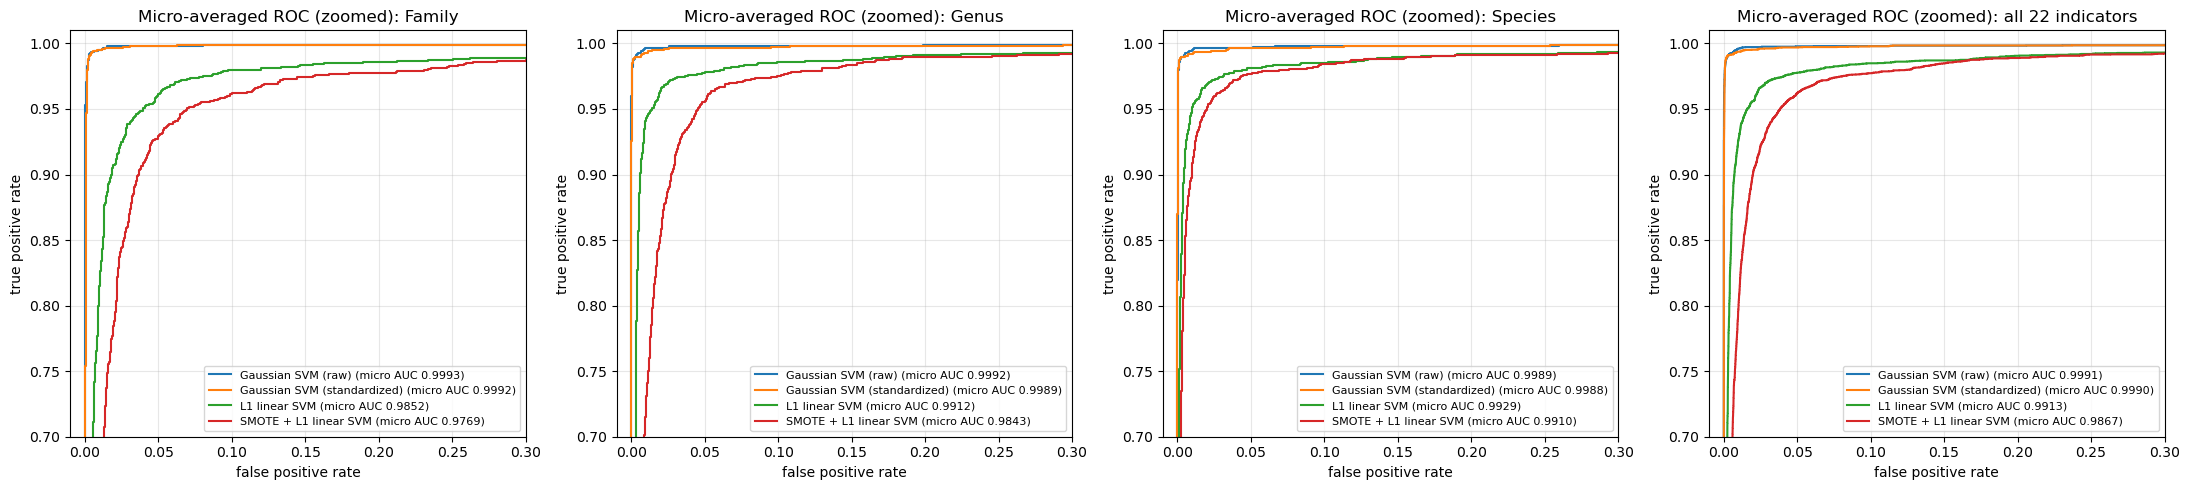

In [14]:
fig, axes = plt.subplots(1, 4, figsize=(22, 5))
offsets = np.cumsum([0] + [len(CLASSES[lab]) for lab in LABELS])
for ax, (j, title) in zip(axes, [(0, "Family"), (1, "Genus"), (2, "Species"), (None, "all 22 indicators")]):
    for name in bin_models:
        Yb, Sb = roc_data[name]
        cols = slice(None) if j is None else slice(offsets[j], offsets[j + 1])
        fpr, tpr, _ = roc_curve(Yb[:, cols].ravel(), Sb[:, cols].ravel())
        ax.plot(fpr, tpr, label=f"{name} (micro AUC {roc_auc_score(Yb[:, cols], Sb[:, cols], average='micro'):.4f})")
    ax.plot([0, 1], [0, 1], "k:", lw=1)
    ax.set_xlim(-0.01, 0.3)
    ax.set_ylim(0.7, 1.01)
    ax.set_xlabel("false positive rate")
    ax.set_ylabel("true positive rate")
    ax.set_title(f"Micro-averaged ROC (zoomed): {title}")
    ax.legend(fontsize=8, loc="lower right")
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

confusion matrices of the model with the highest exact match: Gaussian SVM (raw)


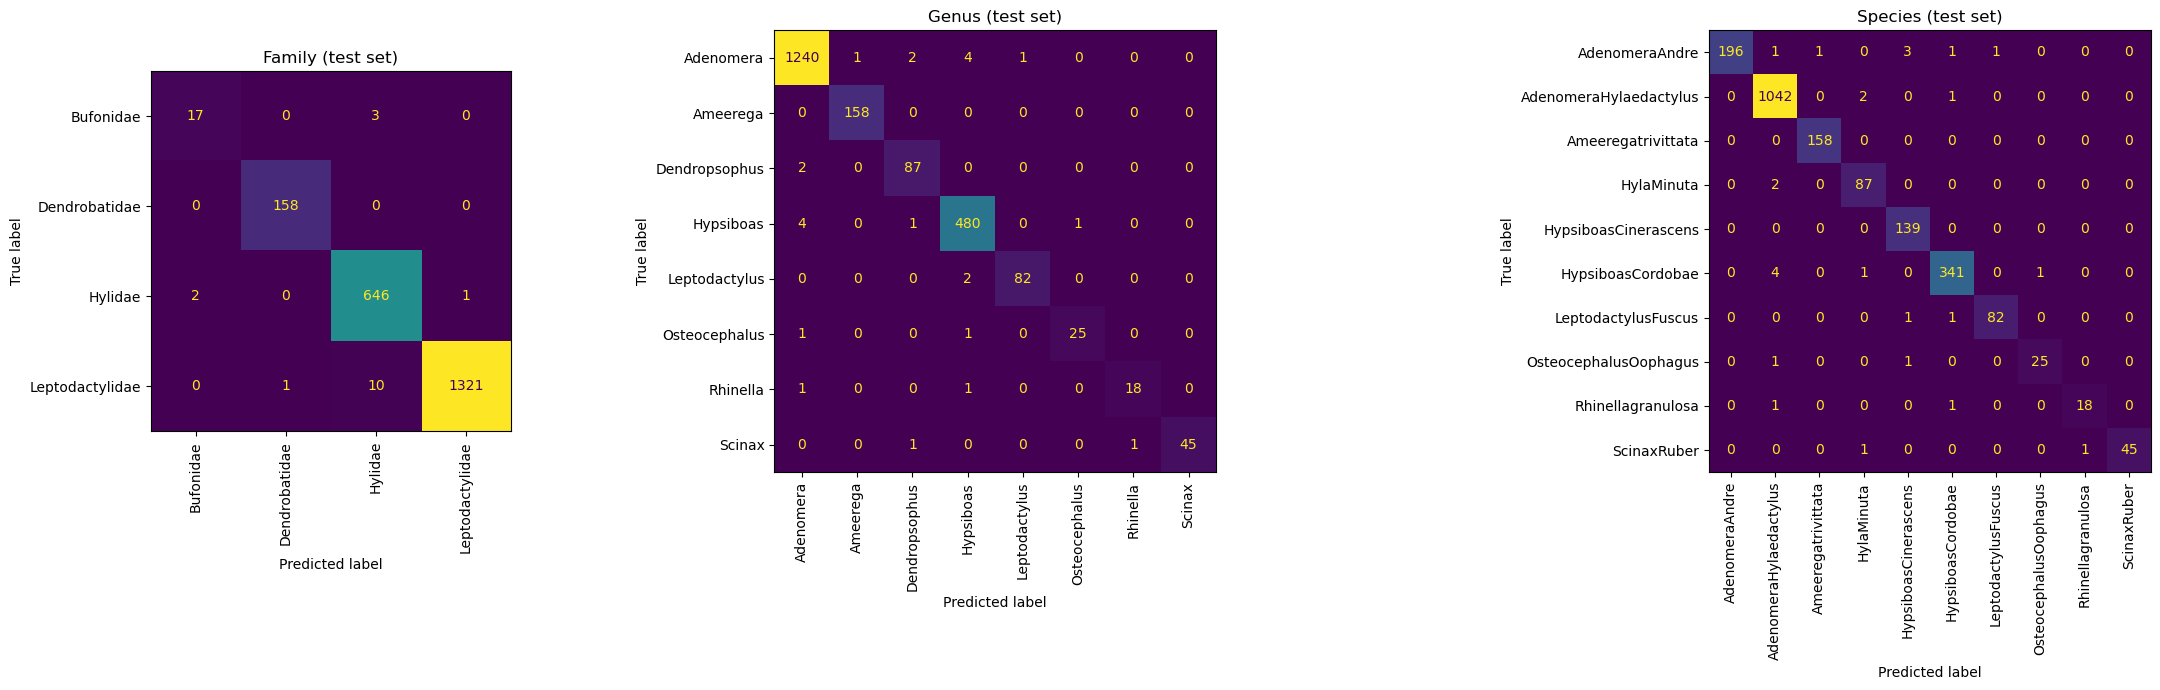

,Bufonidae,Dendrobatidae,Hylidae,Leptodactylidae,Adenomera,Ameerega,Dendropsophus,Hypsiboas,Leptodactylus,Osteocephalus,Rhinella,Scinax,AdenomeraAndre,AdenomeraHylaedactylus,Ameeregatrivittata,HylaMinuta,HypsiboasCinerascens,HypsiboasCordobae,LeptodactylusFuscus,OsteocephalusOophagus,Rhinellagranulosa,ScinaxRuber
TN,2137,2000,1497,826,903,2000,2066,1665,2074,2131,2138,2112,1956,1105,2000,2066,2015,1808,2074,2131,2138,2112
FP,2,1,13,1,8,1,4,8,1,1,1,0,0,9,1,4,5,4,1,1,1,0
FN,3,0,3,11,8,0,2,6,2,2,2,2,7,3,0,2,0,6,2,2,2,2
TP,17,158,646,1321,1240,158,87,480,82,25,18,45,196,1042,158,87,139,341,82,25,18,45


In [15]:
best = max(bin_models, key=lambda n: results[n]["exact match"])
print("confusion matrices of the model with the highest exact match:", best)
fig, axes = plt.subplots(1, 3, figsize=(24, 7), gridspec_kw={"width_ratios": [4, 8, 10]})
for ax, lab in zip(axes, LABELS):
    ConfusionMatrixDisplay.from_predictions(Y_test[lab], predictions[best][lab], labels=CLASSES[lab], ax=ax,
                                            colorbar=False, xticks_rotation=90)
    ax.set_title(f"{lab} (test set)")
plt.tight_layout()
plt.show()

mcm = multilabel_confusion_matrix(roc_data[best][0], np.hstack([label_binarize(predictions[best][lab], classes=CLASSES[lab]) for lab in LABELS]))
names22 = [c for lab in LABELS for c in CLASSES[lab]]
pd.DataFrame(mcm.reshape(len(names22), 4), index=names22, columns=["TN", "FP", "FN", "TP"]).T

**Discussion.** The Gaussian SVMs rank the classes almost perfectly: the macro AUC is about 0.997 and the micro AUC about 0.999 for every label. The micro-averaged precision and recall over the 22 indicators equal the Hamming score (0.990), as they must when every instance has exactly 3 true and 3 predicted classes. The L1 SVM still has a high AUC (macro 0.98), even though it never predicts Bufonidae. Its decision values rank the classes reasonably well, but the one-versus-all argmax never selects Bufonidae. The problem is the decision threshold, not the ranking, and this is what SMOTE changes: over the 22 indicators, macro recall goes up (0.83 → 0.90) while macro precision goes down (0.88 → 0.79), and the AUC stays about the same. In the confusion matrices of the best model, the largest error is between the two large families, Leptodactylidae and Hylidae (11 Leptodactylidae predicted as another family, 13 false positives for Hylidae). The species errors are concentrated in the two *Adenomera* species and *HypsiboasCordobae*.

## 2. K-Means Clustering on a Multi-Class and Multi-Label Data Set

**Procedure (one Monte-Carlo run, with seed $s$):**

- **(a)** Run k-means on all 7,195 rows and the 22 MFCC features (no train/test split, no labels; the features are already normalized, so they are used as they are) for every $k = 2, \dots, 50$, each with 10 random initializations (`n_init=10`, `random_state=s`). Choose $k$ automatically as the $k$ with the largest **average silhouette** $\bar s(k) = \frac1n\sum_i \frac{b_i - a_i}{\max(a_i, b_i)}$, where $a_i$ is the mean distance of $x_i$ to the other points of its cluster and $b_i$ the mean distance to the points of the nearest other cluster. The silhouette is not defined for $k = 1$ (there is no other cluster), so $k = 1$ cannot be selected by this criterion; it is shown separately below as a baseline. (The Calinski–Harabasz index was also computed; on this data it decreases monotonically in $k$ and would always pick $k=2$, so it is not informative.)
- **(b)** In every cluster, find the majority family, genus and species from the true labels.
- **(c)** Assign every point the majority triplet of its cluster and compute the average Hamming distance $\frac1n\sum_i HD_i$, the Hamming loss $\frac{1}{3n}\sum_i HD_i$ and the Hamming score $1 - $ Hamming loss between the true and the assigned triplets (definitions as in 1(b)i).

The procedure is repeated **50 times** with seeds 0, …, 49 (the randomness is the k-means initialization). The 50 runs are run in parallel, each with a single thread.

In [16]:
def majority_assignment(cluster, Y):
    maj = Y.groupby(cluster).agg(lambda s: s.value_counts().idxmax())
    return maj, maj.loc[cluster].reset_index(drop=True)


def kmeans_run(seed, X, Y, ks=range(2, 51)):
    with threadpool_limits(1):
        sil, ch, inertia, labels = [], [], [], {}
        for k in ks:
            km = KMeans(n_clusters=k, n_init=10, random_state=seed).fit(X)
            labels[k] = km.labels_
            sil.append(silhouette_score(X, km.labels_))
            ch.append(calinski_harabasz_score(X, km.labels_))
            inertia.append(km.inertia_)
    k_best = list(ks)[int(np.argmax(sil))]
    cluster = labels[k_best]
    maj, assigned = majority_assignment(cluster, Y)
    s = multilabel_scores(Y, assigned)
    return {"seed": seed, "k": k_best, "silhouette": max(sil), "avg Hamming distance": s["avg Hamming distance"],
            "Hamming loss": s["Hamming loss"], "Hamming score": s["Hamming score"], "exact match": s["exact match"],
            "curves": pd.DataFrame({"silhouette": sil, "Calinski-Harabasz": ch, "within-cluster SS": inertia}, index=list(ks)),
            "cluster": cluster, "majority": maj}


t0 = time.time()
runs = Parallel(n_jobs=N_JOBS)(delayed(kmeans_run)(seed, X_all, Y_all) for seed in range(50))
print("50 Monte-Carlo runs in %.0f s" % (time.time() - t0))

50 Monte-Carlo runs in 950 s


### (a) Choosing $k$ — illustrated for the first run (seed 0)

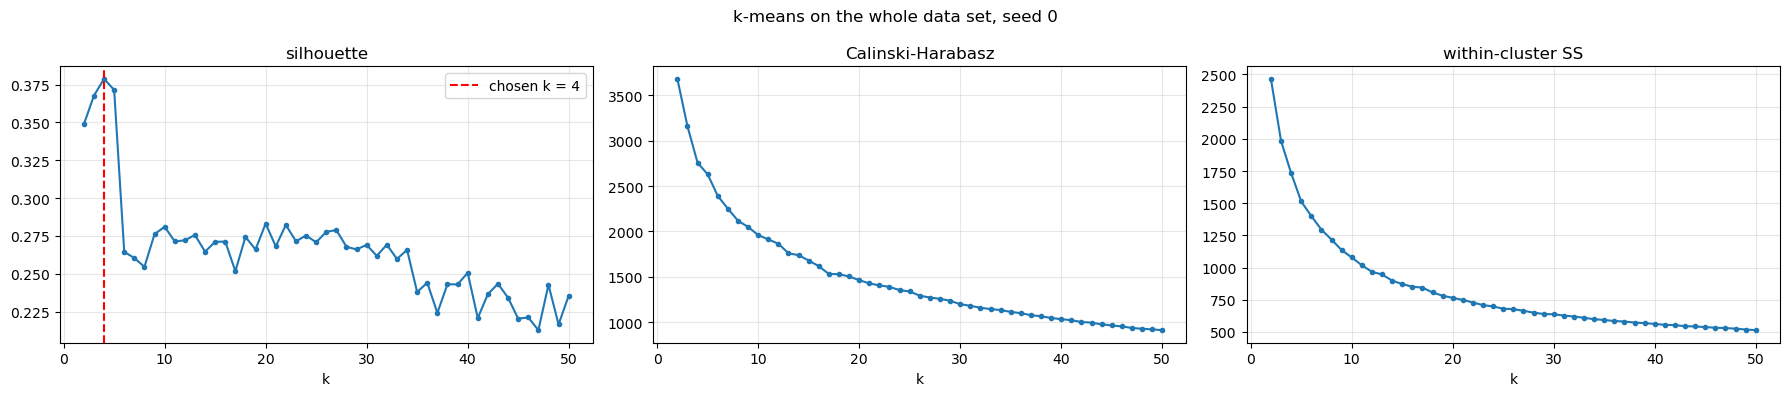

chosen k = 4, average silhouette = 0.3788


In [17]:
r0 = runs[0]
fig, axes = plt.subplots(1, 3, figsize=(18, 4))
for ax, col in zip(axes, r0["curves"].columns):
    ax.plot(r0["curves"].index, r0["curves"][col], "o-", ms=3)
    ax.set_xlabel("k")
    ax.set_title(col)
    ax.grid(alpha=0.3)
axes[0].axvline(r0["k"], color="r", ls="--", label=f"chosen k = {r0['k']}")
axes[0].legend()
fig.suptitle("k-means on the whole data set, seed 0")
plt.tight_layout()
plt.show()
print("chosen k = %d, average silhouette = %.4f" % (r0["k"], r0["silhouette"]))

### (b) Majority family, genus and species in each cluster (seed 0)

In [18]:
c0 = pd.Series(r0["cluster"], name="cluster")
tab = r0["majority"].copy()
tab.insert(0, "size", c0.value_counts().sort_index())
for lab in LABELS:
    tab[f"{lab} purity"] = [np.mean(Y_all[lab][c0 == c] == tab.loc[c, lab]) for c in tab.index]
tab.round(3)

,size,Family,Genus,Species,Family purity,Genus purity,Species purity
0,3568,Leptodactylidae,Adenomera,AdenomeraHylaedactylus,0.972,0.971,0.971
1,1982,Hylidae,Hypsiboas,HypsiboasCordobae,0.628,0.524,0.514
2,1031,Dendrobatidae,Ameerega,Ameeregatrivittata,0.485,0.485,0.485
3,614,Hylidae,Hypsiboas,HypsiboasCinerascens,0.961,0.883,0.736


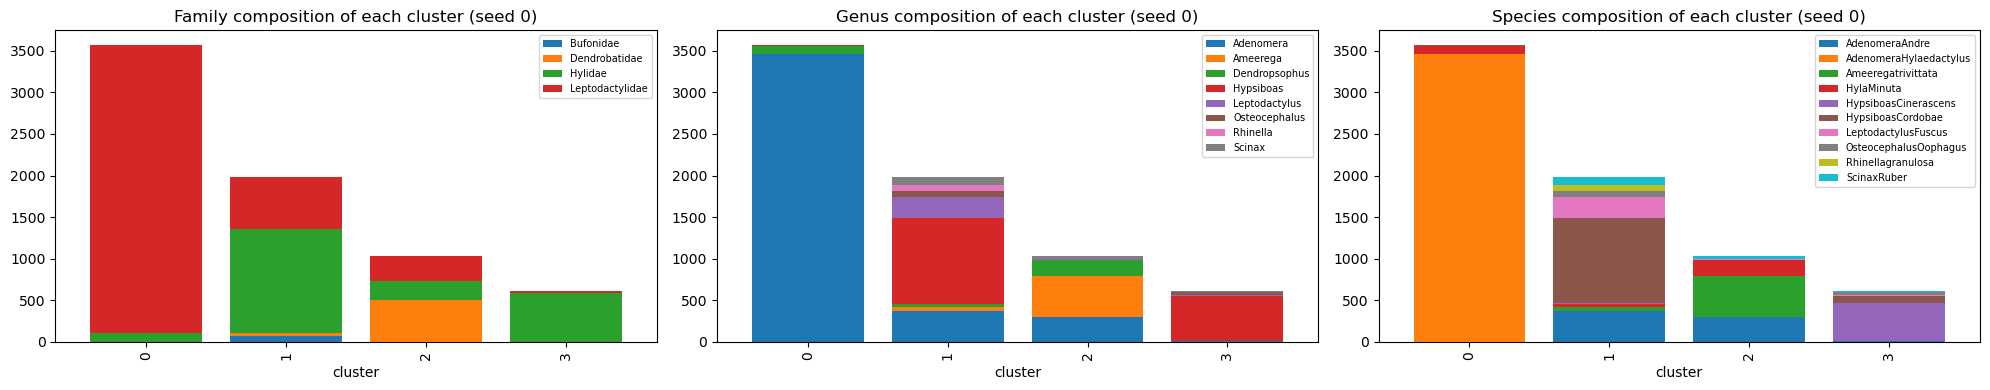

In [19]:
fig, axes = plt.subplots(1, 3, figsize=(20, 4))
for ax, lab in zip(axes, LABELS):
    pd.crosstab(c0, Y_all[lab]).plot.bar(stacked=True, ax=ax, width=0.8)
    ax.set_title(f"{lab} composition of each cluster (seed 0)")
    ax.legend(fontsize=7)
plt.tight_layout()
plt.show()

### (c) Hamming distance, Hamming score and Hamming loss — 50 Monte-Carlo runs

In [20]:
mc = pd.DataFrame([{k: v for k, v in r.items() if k not in ("curves", "cluster", "majority")} for r in runs]).set_index("seed")
print("seed 0: avg Hamming distance = %.4f, Hamming loss = %.4f, Hamming score = %.4f"
      % tuple(mc.loc[0, ["avg Hamming distance", "Hamming loss", "Hamming score"]]))
display(mc.agg(["mean", "std", "min", "max"]).round(4))
print("chosen k in the 50 runs:", mc["k"].value_counts().sort_index().to_dict())

_, base = majority_assignment(np.zeros(len(Y_all), dtype=int), Y_all)
b = multilabel_scores(Y_all, base)
print("baseline k = 1 (every point gets the overall majority triplet %s): avg Hamming distance = %.4f, Hamming loss = %.4f"
      % (tuple(base.iloc[0]), b["avg Hamming distance"], b["Hamming loss"]))

seed 0: avg Hamming distance = 0.6673, Hamming loss = 0.2224, Hamming score = 0.7776


,k,silhouette,avg Hamming distance,Hamming loss,Hamming score,exact match
mean,4.0,0.3792,0.6719,0.2240,0.7760,0.7507
std,0.0,0.0017,0.0170,0.0057,0.0057,0.0178
min,4.0,0.3786,0.6653,0.2218,0.7547,0.6828
max,4.0,0.3853,0.7358,0.2453,0.7782,0.7564


chosen k in the 50 runs: {4: 50}
baseline k = 1 (every point gets the overall majority triplet ('Leptodactylidae', 'Adenomera', 'AdenomeraHylaedactylus')): avg Hamming distance = 1.3255, Hamming loss = 0.4418


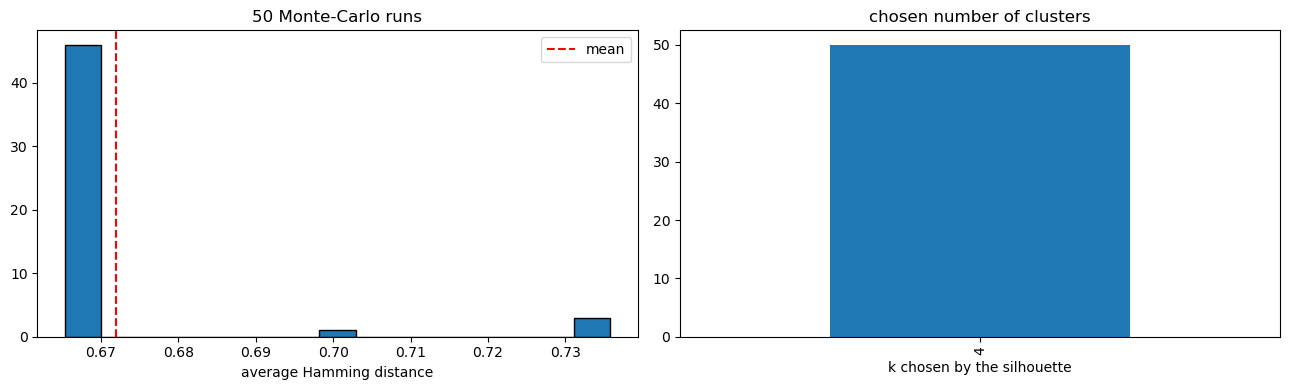

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].hist(mc["avg Hamming distance"], bins=15, edgecolor="k")
axes[0].axvline(mc["avg Hamming distance"].mean(), color="r", ls="--", label="mean")
axes[0].set_xlabel("average Hamming distance")
axes[0].set_title("50 Monte-Carlo runs")
axes[0].legend()
mc["k"].value_counts().sort_index().plot.bar(ax=axes[1])
axes[1].set_xlabel("k chosen by the silhouette")
axes[1].set_title("chosen number of clusters")
plt.tight_layout()
plt.show()

**Discussion.**

- **(a)** In all 50 runs the silhouette chooses **$k = 4$** (average silhouette ≈ 0.379; it is below 0.29 for $k \ge 6$). The Calinski–Harabasz index decreases monotonically and the within-cluster sum of squares has no clear elbow, so the silhouette is the most useful criterion here.
- **(b)** The four clusters roughly follow the four large groups: an almost pure *AdenomeraHylaedactylus* cluster (97% purity), a *HypsiboasCinerascens* / Hylidae cluster, a mixed Hylidae cluster with majority *HypsiboasCordobae* (51% purity at species level), and a mixed cluster with majority *Ameeregatrivittata* that is less than half pure (48.5%). With only 4 clusters at most 4 of the 10 species (here 3 of the 4 families) can ever be assigned, so the small species are never predicted correctly.
- **(c)** Over the 50 Monte-Carlo runs, the **average Hamming distance is 0.6719 with standard deviation 0.0170**. Equivalently, the Hamming loss is 0.2240 ± 0.0057, the Hamming score is 0.7760 ± 0.0057, and the exact match is 0.751 ± 0.018. For comparison, assigning every point the overall majority triplet (k = 1) gives an average Hamming distance of 1.3255, so the unsupervised clusters halve the number of wrong labels. They are still far from the supervised SVMs of Problem 1, whose average Hamming distance is 0.031. The variation between runs is small because `n_init=10` almost always finds the same local optimum; only a few runs converge to a slightly different partition (maximum Hamming distance 0.736).

## 3. ISLR 12.6.2

Dissimilarity matrix of four observations:

$$\begin{bmatrix} & 0.3 & 0.4 & 0.7 \\ 0.3 & & 0.5 & 0.8 \\ 0.4 & 0.5 & & 0.45 \\ 0.7 & 0.8 & 0.45 & \end{bmatrix}$$

**(a) Complete linkage.** The smallest dissimilarity is $d(1,2) = 0.3$, so 1 and 2 fuse at height 0.3. Complete linkage uses the largest pairwise dissimilarity: $d(\{1,2\},3) = \max(0.4, 0.5) = 0.5$, $d(\{1,2\},4) = \max(0.7, 0.8) = 0.8$, $d(3,4) = 0.45$. The smallest is 0.45, so 3 and 4 fuse at height 0.45. Finally $d(\{1,2\},\{3,4\}) = \max(0.4, 0.5, 0.7, 0.8) = 0.8$, so the two clusters fuse at height 0.8.

**(b) Single linkage.** Again 1 and 2 fuse first at 0.3. Single linkage uses the smallest pairwise dissimilarity: $d(\{1,2\},3) = \min(0.4, 0.5) = 0.4$, $d(\{1,2\},4) = \min(0.7, 0.8) = 0.7$, $d(3,4) = 0.45$. The smallest is 0.4, so 3 joins $\{1,2\}$ at height 0.4. Finally $d(\{1,2,3\},4) = \min(0.7, 0.8, 0.45) = 0.45$, so 4 joins at height 0.45.

The dendrograms (drawn with `scipy` from the same matrix) are shown below; the fusion heights agree with the hand computation.

complete linkage (cluster i, cluster j, height, size):
 [[0.   1.   0.3  2.  ]
 [2.   3.   0.45 2.  ]
 [4.   5.   0.8  4.  ]]
single linkage:
 [[0.   1.   0.3  2.  ]
 [2.   4.   0.4  3.  ]
 [3.   5.   0.45 4.  ]]


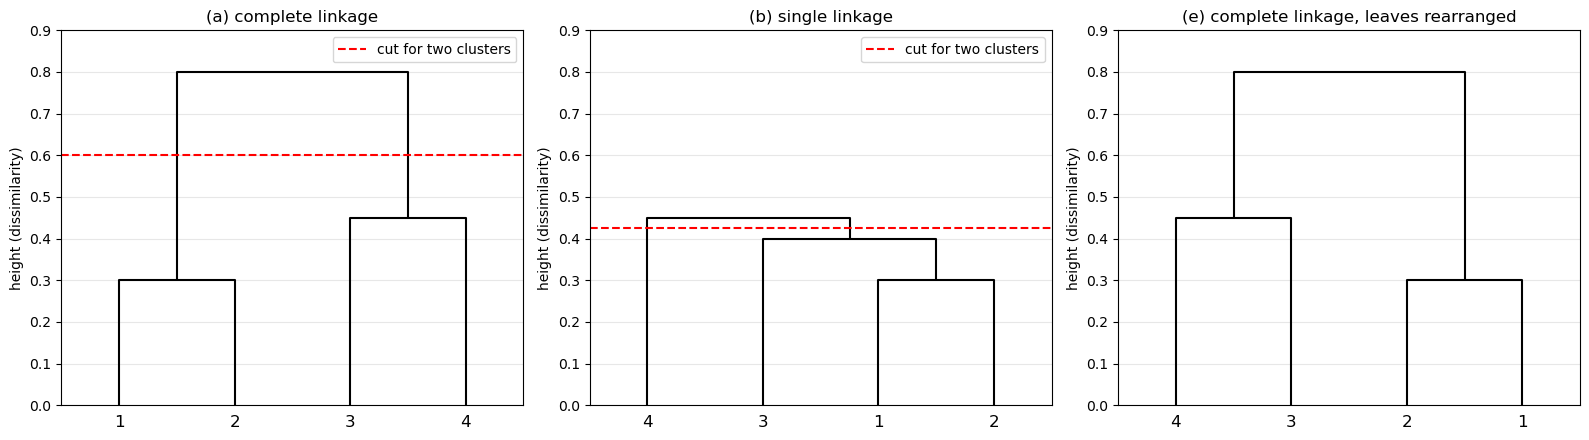

In [22]:
D = np.array([[0, 0.3, 0.4, 0.7], [0.3, 0, 0.5, 0.8], [0.4, 0.5, 0, 0.45], [0.7, 0.8, 0.45, 0]])
Z_complete = linkage(squareform(D), method="complete")
Z_single = linkage(squareform(D), method="single")
print("complete linkage (cluster i, cluster j, height, size):\n", Z_complete)
print("single linkage:\n", Z_single)

# (e): the same tree as (a) with the two children of every fusion swapped
Z_swapped = Z_complete.copy()
Z_swapped[:, [0, 1]] = Z_swapped[:, [1, 0]]

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, Z, t, cut in zip(axes, [Z_complete, Z_single, Z_swapped],
                         ["(a) complete linkage", "(b) single linkage", "(e) complete linkage, leaves rearranged"],
                         [None, None, None]):
    dendrogram(Z, labels=[1, 2, 3, 4], ax=ax, color_threshold=0, above_threshold_color="k")
    ax.set_title(t)
    ax.set_ylabel("height (dissimilarity)")
    ax.set_ylim(0, 0.9)
    ax.grid(axis="y", alpha=0.3)
axes[0].axhline(0.6, color="r", ls="--", label="cut for two clusters")
axes[1].axhline(0.425, color="r", ls="--", label="cut for two clusters")
axes[0].legend()
axes[1].legend()
plt.tight_layout()
plt.show()

**(c)** Cutting the complete-linkage dendrogram so that there are two clusters (any height between 0.45 and 0.8) gives the clusters $\{1, 2\}$ and $\{3, 4\}$.

**(d)** Cutting the single-linkage dendrogram so that there are two clusters (any height between 0.4 and 0.45) gives the clusters $\{1, 2, 3\}$ and $\{4\}$.

**(e)** The two branches at every fusion can be swapped without changing the meaning of the dendrogram, because only the heights of the fusions carry information, not the left/right order. For example, swapping 1 with 2 and 3 with 4, and the two main branches, gives the leaf order 4, 3, 2, 1 (third panel above): 1 and 2 still fuse at 0.3, 3 and 4 at 0.45, and the two groups at 0.8, exactly as in (a).